# Fashion-MNIST CNN 수행평가
# 파일명 변경하기: 1315정서진-수행(2).ipynb

**Fashion MNIST 데이터셋을 이용해 의류 이미지를 분류하는 CNN 모델을 직접 구현하고 실험합니다.**

**진행 안내**
- AI활용 가능
- **①~④ 교사 제공 코드:** 수정하지 않고 순서대로 실행합니다.
- **⑤~⑧ 학생 활동:** 직접 코딩하거나 값을 입력합니다.
- **⑦에서 검증 정확도·손실을 비교해 모델을 선택한 다음, ⑧에서 테스트**합니다.
- **제출:** 실행 결과를 포함한 `.ipynb` 파일 및 '.html'

> **평가 실험 조건**: 기준(5 Epoch, Dense 64) / A(Epoch만 6~12 중 선택, Dense 64) / B(Epoch 5 고정, Dense만 32~128 중 선택·64 제외). 모든 값은 정수로 입력합니다.

## ① 도구 불러오기 — 교사 제공
- **TensorFlow/Keras**: CNN 모델 구현 도구
- **Matplotlib**: 이미지 확인 도구

아래 셀을 실행하세요.

In [1]:
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("라이브러리 준비 완료")

라이브러리 준비 완료


## ② Fashion-MNIST 데이터셋 불러오기 — 교사 제공
- **Fashion-MNIST**: 의류 이미지 10종류를 분류하는 데이터셋 (28×28 흑백 이미지)
- **x**: 이미지(입력값), **y**: 정답 레이블(0~9)
- 원본 데이터: 훈련용 60,000장, 테스트용 10,000장

In [2]:
# 학습용(train)과 테스트용(test) 데이터 불러오기
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# 정답 레이블 0~9의 의류 종류
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("학습용 이미지:", x_train.shape)
print("테스트용 이미지:", x_test.shape)
print("첫 번째 이미지 정답:", y_train[0], class_names[y_train[0]])

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
학습용 이미지: (60000, 28, 28)
테스트용 이미지: (10000, 28, 28)
첫 번째 이미지 정답: 9 Ankle boot


## ③ 의류 이미지 확인하기 — 교사 제공

첫 번째 이미지와 학습 데이터의 앞 10개 이미지를 확인합니다. 아직 모델을 학습시키는 단계는 아닙니다.

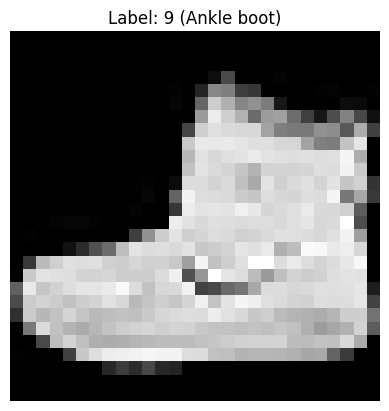

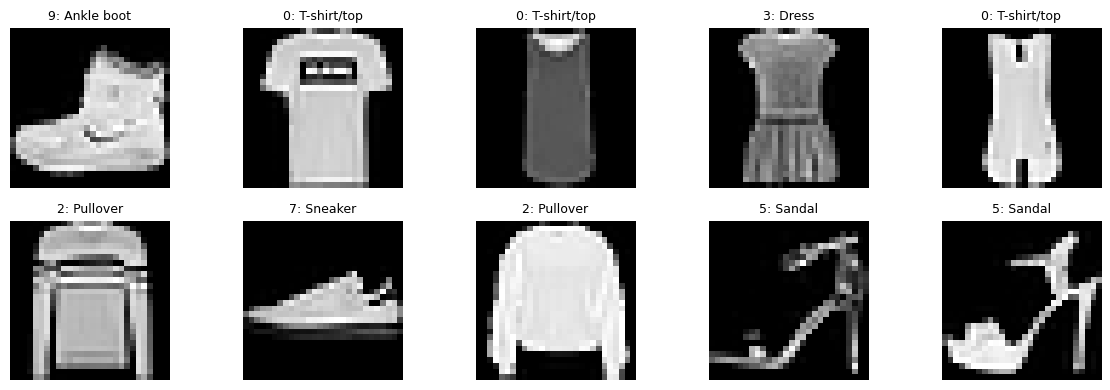

In [3]:
# 첫 번째 의류 이미지 표시
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]} ({class_names[y_train[0]]})")
plt.axis("off")
plt.show()

# 앞의 10개 이미지 확인
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"{y_train[i]}: {class_names[y_train[i]]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## ④ 학습 데이터 준비하기 — 교사 제공
- **주의:** 아래 전처리 코드는 데이터를 다시 불러오지 않은 상태에서 반복 실행하지 마세요.

- 실행 시간을 줄이기 위해 **훈련용 후보 12,000장**, **테스트용 2,000장**만 사용합니다.
- **정규화:** 픽셀값(0~255)을 0~1로 변환합니다 (`/255.0`).
- **흑백 채널 추가:** CNN 입력 형태를 `(28, 28, 1)`로 맞춥니다.

In [4]:
# 정규화 전 픽셀값 확인
print("정규화 전 최댓값:", x_train.max())
print("정규화 전 최솟값:", x_train.min())

# 데이터 개수 선택 + 정규화
x_train = x_train[:12000].astype("float32") / 255.0
y_train = y_train[:12000]
x_test = x_test[:2000].astype("float32") / 255.0
y_test = y_test[:2000]

print("정규화 후 최댓값:", x_train.max())
print("정규화 후 최솟값:", x_train.min())

# CNN 입력을 위해 채널 차원 추가
x_train = x_train[..., None]
x_test = x_test[..., None]
print("훈련 데이터 형태:", x_train.shape)
print("테스트 데이터 형태:", x_test.shape)

정규화 전 최댓값: 255
정규화 전 최솟값: 0
정규화 후 최댓값: 1.0
정규화 후 최솟값: 0.0
훈련 데이터 형태: (12000, 28, 28, 1)
테스트 데이터 형태: (2000, 28, 28, 1)


## ⑤ CNN 모델 만들기 — 직접 코딩 (15점)
keras.Sequential()을 이용해 CNN 모델을 직접 생성하고 컴파일하시오. 은닉층 뉴런 수는 64개로 설정
| 구성 순서 | 층 및 설정 | 역할 |
|---|---|---|
| 1 | `Input(shape=(28, 28, 1))` | 이미지 입력 |
| 2 | `Conv2D(16, (3, 3), activation="relu")` | 이미지 특징 추출 |
| 3 | `MaxPooling2D((2, 2))` | 특징 맵 크기 축소 |
| 4 | `Flatten()` | 1차원 변환 |
| 5 | `Dense(64, activation="relu")` | 은닉층에서 특징 학습 |
| 6 | `Dense(10, activation="softmax")` | 의류 10종류 확률 출력 |

**모델 컴파일 조건**: `optimizer="adam"`, `loss="sparse_categorical_crossentropy"`, `metrics=["accuracy"]`.


In [5]:
# ⑤ CNN 모델 생성 및 컴파일 — (코드 작성하기)

keras.utils.set_random_seed(42)

# 1. keras.Sequential()을 이용하여 CNN 모델을 생성한다.
#    - Input: (28, 28, 1)
#    - Conv2D: 필터 16개, 커널 (3, 3), ReLU
#    - MaxPooling2D: (2, 2)
#    - Flatten
#    - Dense: 뉴런 64개, ReLU
#    - Dense: 뉴런 10개, Softmax
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# 2. model.compile()을 작성한다.
#    - optimizer: adam
#    - loss: sparse_categorical_crossentropy
#    - metrics: accuracy
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


## ⑥ CNN 학습하기 — 직접 코딩  (5점)

⑤에서 생성한 CNN모델을 **기준 조건(Epoch 5, Dense 64)**으로 학습하시오.
- `fit()` 학습 조건: `epochs=5`, `batch_size=32`, `validation_split=0.2`

In [6]:
# 기준 모델 학습하기(코드 작성하기)
# fit: 학습용 이미지(x_train)와 정답(y_train)으로 CNN 모델 학습

# fit: x_train, y_train으로 학습하기
# Epoch 5회, batch_size 32, validation_split 0.2로 설정하기
# 코드 작성
history = model.fit(x_train, y_train, epochs=5, batch_size=32, validation_split=0.2)


Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.7679 - loss: 0.6691 - val_accuracy: 0.8433 - val_loss: 0.4719
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8559 - loss: 0.4202 - val_accuracy: 0.8562 - val_loss: 0.4200
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8760 - loss: 0.3588 - val_accuracy: 0.8721 - val_loss: 0.3818
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8898 - loss: 0.3171 - val_accuracy: 0.8742 - val_loss: 0.3704
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9022 - loss: 0.2841 - val_accuracy: 0.8788 - val_loss: 0.3659


## ⑦ 기준·A·B 3개 모델 비교 실험 - 직접 코딩  (15점)

연습 노트북과 달리, **A 모델과 B 모델의 변경값은 학생이 범위 안에서 직접 선택합니다.**

| 모델 | Epoch | Dense 은닉층 뉴런 | 변경할 조건 |
|---|---:|---:|---|
| **기준** | **5 (고정)** | **64 (고정)** | 없음 |
| **A** | **6~12 중 정수 1개 선택** | **64 (고정)** | Epoch만 변경 |
| **B** | **5 (고정)** | **32~128 중 정수 1개 선택 (64 제외)** | Dense만 변경 |

**예시:** A는 Epoch 7, B는 Dense 70도 가능합니다.**

**실험 규칙**
1. ⑦코드의 `A_EPOCH`, `B_DENSE`에 **본인이 선택한 정수**를 입력합니다.
2. 기준 ↔ A는 **Epoch만**, 기준 ↔ B는 **Dense 뉴런 수만** 다르게 합니다.
3. 세 모델은 **동일한 훈련·검증 데이터를 사용**하고, 각각 **새 모델로 생성하여 학습**합니다.
4. 모든 실험에서 `batch_size=32`, `validation_split=0.2`, Adam 및 모델의 다른 층 구성은 동일하게 유지합니다.

### ⑦-1 기준·A·B 모델의 실험 조건 직접 입력

A 모델의 Epoch와 B 모델의 Dense 뉴런 수를 선택하세요.

<질문에 대한 예상 답안을 직접 작성하기>

A 모델의 Epoch 선택 이유와 예상 결과
: 에포크를 늘리면 (검증 정확도가 더 높아질 수 있지만, 과적합이 생길 수 있다고) 예상함.

B 모델의 Dense 뉴런 수 선택 이유와 예상 결과:
: 뉴런수를 늘리면 (더 다양한 특징을 학습할 수 있지만, 과적합이 생길 수 있다고) 예상함.

### ⑦-2 독립적인 모델 3개 생성·학습 — 직접 코딩

기준모델·A모델·B모델을 각각 새로 생성하고 학습한 후, 훈련·검증 정확도와 손실값을 확인하세요.

아래 반복문을 완성하여 **기준·A·B의 CNN 모델을 각각 새로 생성**하세요.
- 매 반복마다 시드를 `42`로 고정합니다.
- 학습 조건: `epochs=epochs`, `batch_size=32`, `validation_split=0.2`
- 학습한 모델은 `models[name]`에 보관합니다.
- 마지막 Epoch의 **훈련 정확도·손실**과 **검증 정확도·손실**을 출력합니다.

In [ ]:
# 기준·A·B 세 모델을 독립적으로 학습하시오.(코드 작성하기)

# A_EPOCH: 6~12 사이의 정수 선택
# B_DENSE: 32~128 사이의 정수 선택 (64 제외)
# 위 두 변수에 학생이 직접 값을 지정하세요.
# 세 모델을 한 번에 학습하고 훈련·검증 결과 확인

A_EPOCH = 10
B_DENSE = 128

plans = [("기준", 5, 64), ("A", A_EPOCH, 64), ("B", 5, B_DENSE)]
models = {}

for name, epochs, units in plans:
    keras.utils.set_random_seed(42)
    # 1. keras.Sequential()로 새 CNN 모델 생성
    #    Dense 은닉층에는 units 변수 사용
    m = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    # 2. m.compile() 작성
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    # 3. h = m.fit() 작성
    #    epochs=epochs
    #    batch_size=32
    #    validation_split=0.2
    h = m.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_split=0.2, verbose=2)

    # 4. models[name]에 학습한 모델 저장
    models[name] = m

    # 5. 마지막 Epoch의 훈련·검증
    #    정확도와 손실값 출력
    print(f"{name} (Epoch={epochs}, Dense={units})")
    print(f"  훈련: 정확도 {h.history['accuracy'][-1]*100:.2f}%, 손실 {h.history['loss'][-1]:.4f}")
    print(f"  검증: 정확도 {h.history['val_accuracy'][-1]*100:.2f}%, 손실 {h.history['val_loss'][-1]:.4f}")

    # 학생이 코드를 완성한 뒤 삭제



Epoch 1/5
300/300 - 10s - 33ms/step - accuracy: 0.7679 - loss: 0.6691 - val_accuracy: 0.8433 - val_loss: 0.4719
Epoch 2/5
300/300 - 5s - 17ms/step - accuracy: 0.8559 - loss: 0.4202 - val_accuracy: 0.8562 - val_loss: 0.4200
Epoch 3/5
300/300 - 5s - 15ms/step - accuracy: 0.8760 - loss: 0.3588 - val_accuracy: 0.8721 - val_loss: 0.3818
Epoch 4/5
300/300 - 4s - 13ms/step - accuracy: 0.8898 - loss: 0.3171 - val_accuracy: 0.8742 - val_loss: 0.3704
Epoch 5/5
300/300 - 7s - 23ms/step - accuracy: 0.9022 - loss: 0.2841 - val_accuracy: 0.8788 - val_loss: 0.3659
기준 (Epoch=5, Dense=64)
  훈련: 정확도 90.22%, 손실 0.2841
  검증: 정확도 87.88%, 손실 0.3659
Epoch 1/10
300/300 - 5s - 18ms/step - accuracy: 0.7679 - loss: 0.6691 - val_accuracy: 0.8433 - val_loss: 0.4719
Epoch 2/10
300/300 - 5s - 16ms/step - accuracy: 0.8559 - loss: 0.4202 - val_accuracy: 0.8562 - val_loss: 0.4200
Epoch 3/10
300/300 - 6s - 20ms/step - accuracy: 0.8760 - loss: 0.3588 - val_accuracy: 0.8721 - val_loss: 0.3818
Epoch 4/10
300/300 - 4s - 15m

## ⑧ 검증 결과로 모델 선정 후 최종 테스트 — 학생 직접 코딩 (5점)

1. ⑦에서 출력한 **기준/A/B 모델의 검증 정확도와 검증 손실값을 비교**합니다.
2. 최종 선택한 모델 이름을 `choice`에 적고, 선택한 이유는 결과 해석 학습지에 작성합니다.
3. 선택을 완료한 다음에만 `evaluate(x_test, y_test)`로 테스트 정확도·손실값을 확인합니다.

> **주의:** 테스트 결과를 미리 보고 모델을 선택하거나 변경하지 않습니다.

In [ ]:
# [학생 작성] 최종 모델 선정 및 테스트

choice = "A"  # 기준, A, B 중 선택

if choice not in models:
    raise ValueError("기준, A, B 중 선택하세요.")

# models[choice]로 최종 모델 가져오기
# evaluate()로 테스트 손실값과 정확도 구하기
# 선정 모델 이름 출력하기
# 테스트 정확도(%)와 손실값 출력하기
# 코딩하기
final_model = models[choice]
test_loss, test_accuracy = final_model.evaluate(x_test, y_test, verbose=0)
print(f"선정 모델: {choice}")
print(f"테스트 정확도: {test_accuracy * 100:.2f}%")
print(f"테스트 손실: {test_loss:.4f}")


선정 모델: A
테스트 정확도: 88.30%
테스트 손실: 0.3611


---
### 제출 파일
1. 파일-다운로드-.ipnb 제출
2. html로 변환하여 제출